# Anomaly detection in time series

The core functionality of ``dtaianomaly`` is to offer a simple interface for time series anomaly detection. Below, we illustrate how anomalies can be detected in time series using ``dtaianomaly``.

In [1]:
from dtaianomaly.data import UCRLoader
from dtaianomaly.visualization import plot_demarcated_anomalies, plot_anomaly_scores
from dtaianomaly.preprocessing import MovingAverage
from dtaianomaly.anomaly_detection import HydraAD
from dtaianomaly.pipeline import Pipeline
from dtaianomaly.thresholding import FixedCutoffThreshold
from dtaianomaly.evaluation import Precision, Recall, FBeta, AreaUnderROC, AreaUnderPR, VolumeUnderPR, UCRScore, ThresholdMetric

## Load and plot the data

We will illustrate how to detect anomalies with ``dtaianomaly`` using a time series of the [UCR time series anomaly archive](https://www.cs.ucr.edu/~eamonn/time_series_data_2018/UCR_TimeSeriesAnomalyDatasets2021.zip), which is included in the [data folder](../data) of this repository. This time series can easily be loaded using the ``UCRLoader``. Each time series in the UCR archive consists of a normal training part ``X_train``, followed by a test part ``X_test`` that contains exactly one anomaly. Below, we load the data and plot the test data using the ``plot_demarcated_anomalies`` method.

In [2]:
data_loader = UCRLoader("../data/UCR-time-series-anomaly-archive/002_UCR_Anomaly_DISTORTED2sddb40_35000_56600_56900.txt")
data = data_loader.load()
X_train, X_test, y_test = data.X_train, data.X_test, data.y_test
X_train.shape, X_test.shape

((35000,), (45001,))

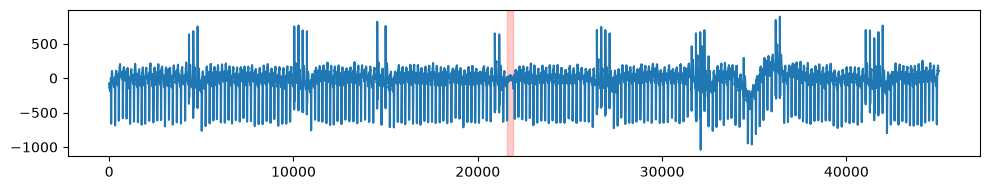

In [3]:
plot_demarcated_anomalies(X_test, y_test, figsize=(10, 2)).tight_layout()

## Anomaly detection

In general, [any anomaly detector](https://dtaianomaly.readthedocs.io/en/stable/getting_started/anomaly_detection.html) in ``dtaianomaly`` can be used to detect anomalies in this time series. Here, we use ``HydraAD``, with a window size that is automatically computed using the Fourier transform. The seed is fixed to obtain the same figure as in the README.

In [4]:
detector = HydraAD(window_size="fft", seed=0)

Now that the detector has been initialized, we fit it on the normal training data and compute the anomaly scores of the test data. The ``predict_proba`` method returns anomaly scores in the interval $[0, 1]$, in which a higher score means more anomalous.

In [5]:
detector.fit(X_train)
y_pred = detector.predict_proba(X_test)

Below, we plot the time series again, as well as the predicted anomaly scores, and see that the highest anomaly scores nicely align with the anomaly!

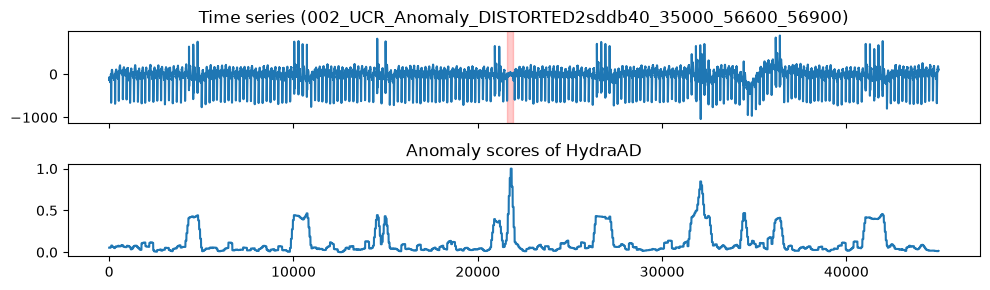

In [6]:
fig = plot_anomaly_scores(X_test, y_test, y_pred, figsize=(10, 3))
fig.axes[0].set_title(f'Time series ({data_loader.path.split("/")[-1].rsplit(".", 1)[0]})')
fig.axes[1].set_title('Anomaly scores of HydraAD')
fig.tight_layout()
fig.savefig('example-README.svg', bbox_inches='tight')

## Anomaly detection with a Pipeline

Before detecting anomalies, we can preprocess the time series. In ``dtaianomaly``, this can be done automatically using a ``Pipeline``. Upon initialization, we simply pass the preprocessors we want to apply, as well as the detector. The fit and predict methods will automatically process the data before detecting anomalies. Below, we apply ``MovingAverage`` to remove some of the noise from the time series before detecting anomalies with ``HydraAD``. Note that it is also possible to pass a list of preprocessors to apply multiple preprocessing steps before detecting anomalies.

In [7]:
pipeline = Pipeline(
    preprocessor=MovingAverage(window_size=10),
    detector=HydraAD(window_size="fft", seed=0)
)
y_pred_pipeline = pipeline.fit(X_train).predict_proba(X_test)

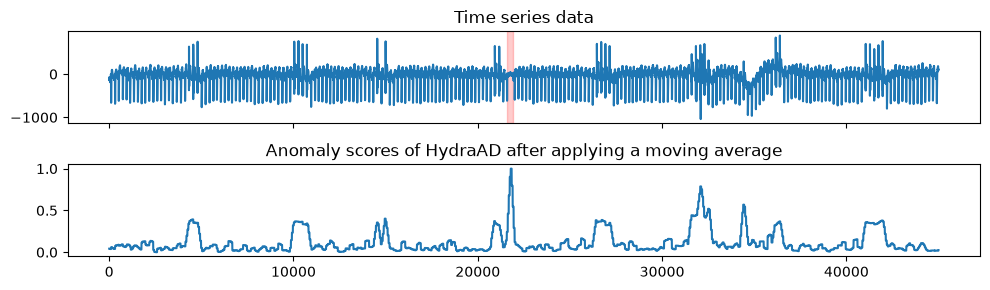

In [8]:
fig = plot_anomaly_scores(X_test, y_test, y_pred_pipeline, figsize=(10, 3))
fig.axes[1].set_title('Anomaly scores of HydraAD after applying a moving average')
fig.tight_layout()

## Quantitative evaluation

Besides visually checking the performance of an anomaly detector, it is also important to quantitatively measure how accurately the anomalies are detected. Below, we first compute the ``Precision`` and ``Recall``. However, the precision and recall require binary labels, while the predicted anomaly scores are continuous. For this reason, we apply ``FixedCutoffThreshold`` thresholding to convert all scores above 0.9 to 1 ("anomaly") and the scores below 0.9 to 0 ("normal").

In [9]:
thresholding = FixedCutoffThreshold(0.9)
y_pred_binary = thresholding.threshold(y_pred)
print('Precision:', Precision().compute(y_test, y_pred_binary))
print('Recall:', Recall().compute(y_test, y_pred_binary))

Precision: 1.0
Recall: 0.17666666666666667


Alternatively to manually applying a threshold to convert the continuous scores to binary predictions, you can initialize a ``ThresholdMetric``, which will automatically apply a specified thresholding strategy before using a binary evaluation metric. Below, we use the same thresholding as above, but compute the ``FBeta`` score with $\beta=1$.

In [10]:
print('F1:', ThresholdMetric(thresholding, FBeta(1.0)).compute(y_test, y_pred))

F1: 0.30028328611898014


We also compute the ``AreaUnderROC``, ``AreaUnderPR`` and ``VolumeUnderPR``. Because these metrics create a curve for all possible thresholds, we can simply pass the predicted, continuous anomaly scores, as shown below. Here, we see that applying a moving average before detecting anomalies improves the performance of ``HydraAD``.

In [11]:
for name, scores in [('HydraAD', y_pred), ('Pipeline', y_pred_pipeline)]:
    print(f'{name}:')
    print('  AUC-ROC:', AreaUnderROC().compute(y_test, scores))
    print('  AUC-PR:', AreaUnderPR().compute(y_test, scores))
    print('  VUS-PR:', VolumeUnderPR().compute(y_test, scores))

HydraAD:
  AUC-ROC: 0.9828912104874613
  AUC-PR: 0.5913643732069574
  VUS-PR: 0.4785632937309017
Pipeline:
  AUC-ROC: 0.9846262201442175
  AUC-PR: 0.687256483817957
  VUS-PR: 0.6234465721373422


Lastly, because each time series in the UCR archive contains exactly one anomaly, we can also compute the ``UCRScore``. This score equals 1 if the highest anomaly score is located near the anomaly, and 0 otherwise.

In [12]:
print('UCR-score:', UCRScore().compute(y_test, y_pred))

UCR-score: 1.0
